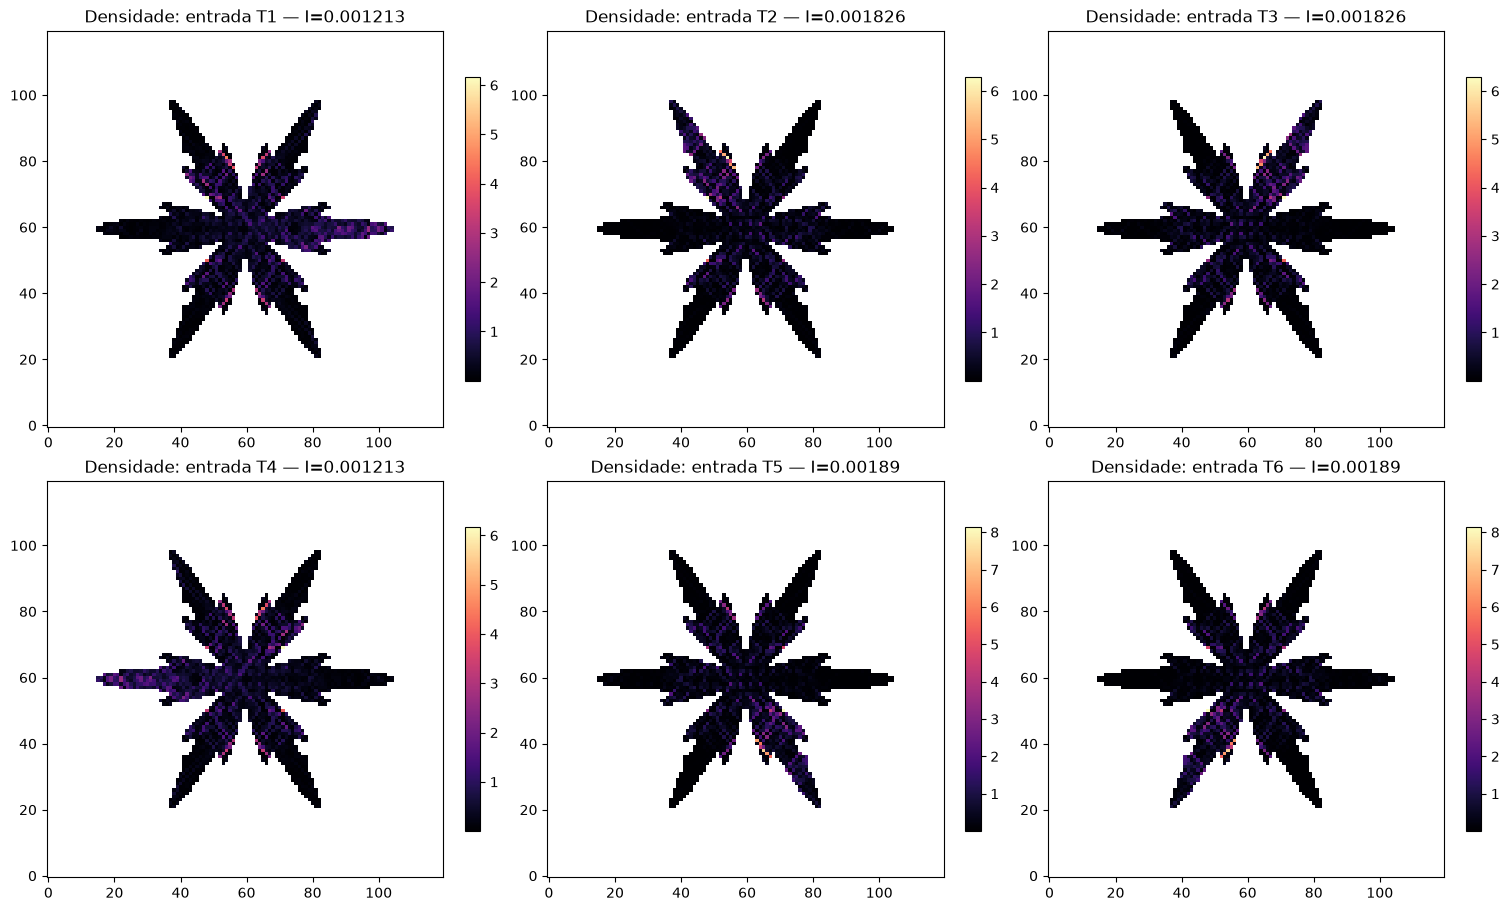

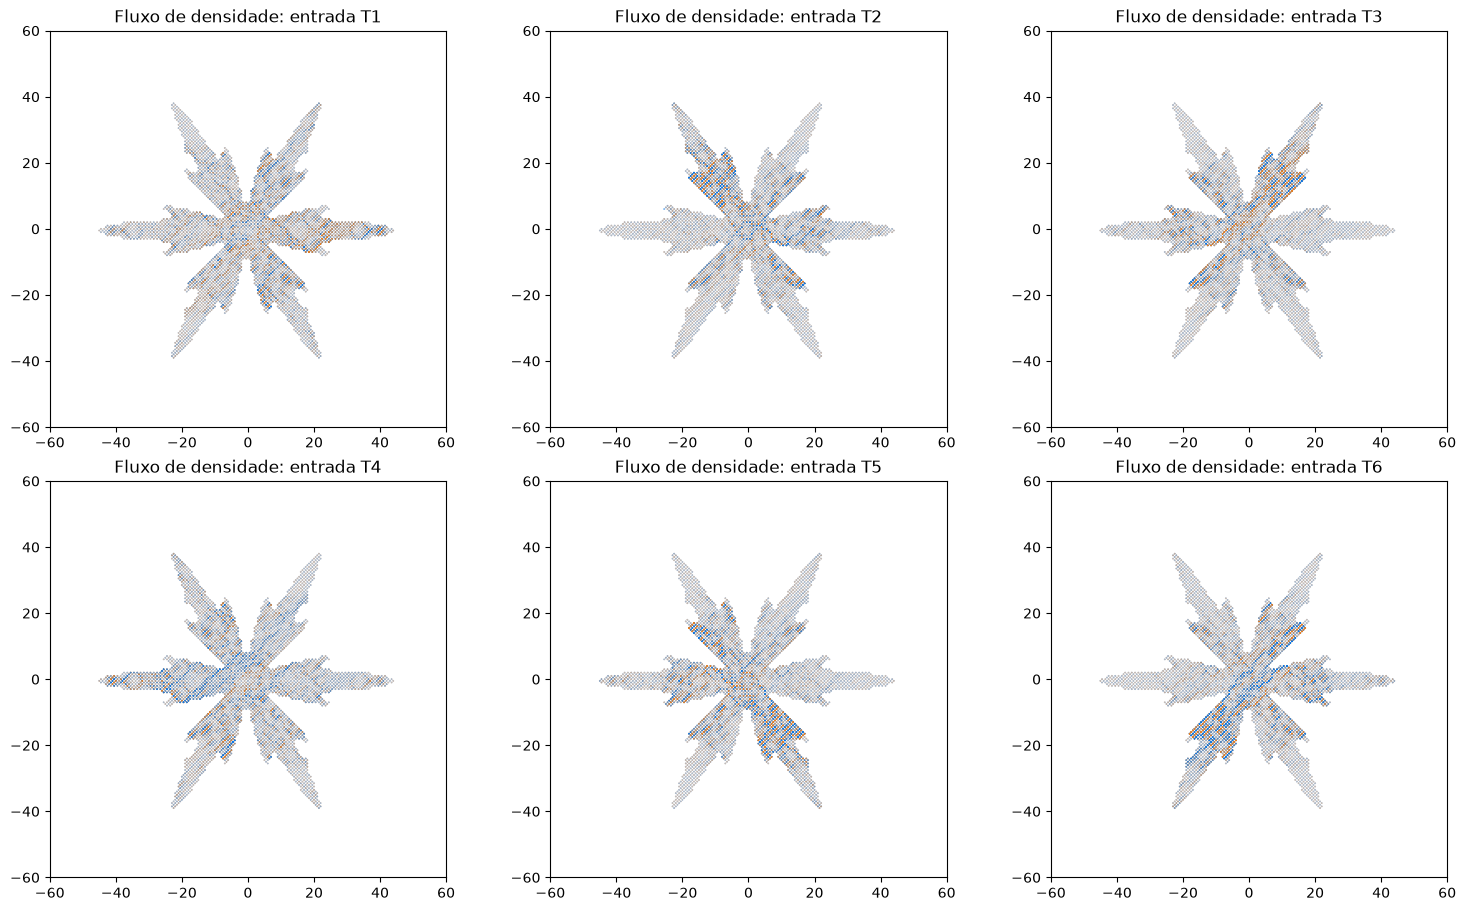

Mapas salvos em ../figures/local_density_deformed.png e ../figures/current_flow_deformed.png


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path('../data')
FIGURES_DIR = Path('../figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with np.load(DATA_DIR / 'geometries.npz') as geometry:
    mask = geometry['mask']
with np.load(DATA_DIR / 'local_deformed.npz') as local:
    densities = local['densities']
    current_links = local['current_links']
    iniquities = local['iniquities']
    site_positions = local['site_positions']
    link_positions = local['link_positions']

height, width = mask.shape
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

for source, ax in enumerate(axes.ravel()):
    density_grid = np.full((height, width), np.nan)
    for position, density in zip(site_positions, densities[source]):
        x, y = np.rint(position).astype(int)
        mx = x + width // 2
        my = y + height // 2
        if 0 <= mx < width and 0 <= my < height:
            density_grid[mx, my] = density

    image = ax.imshow(density_grid.T, origin='lower', cmap='magma', interpolation='nearest')
    ax.set_aspect('equal')
    ax.set_title(f'Densidade: entrada T{source+1} — I={iniquities[source]:.4g}')
    fig.colorbar(image, ax=ax, fraction=0.035)

output_density = FIGURES_DIR / 'local_density_deformed.png'
fig.savefig(output_density, dpi=220, bbox_inches='tight')

fig_flow, axes_flow = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for source, ax in enumerate(axes_flow.ravel()):
    for (start, end), value in zip(link_positions, current_links[source]):
        mx = 0.5 * (start[0] + end[0])
        my = 0.5 * (start[1] + end[1])
        dx = end[0] - start[0]
        dy = end[1] - start[1]
        ax.arrow(mx, my, 0.20 * dx, 0.20 * dy,
                 color='#0877e8' if value >= 0 else '#e67e22',
                 alpha=min(1.0, 0.25 + abs(float(value))),
                 width=0.015,
                 head_width=0.18,
                 length_includes_head=True)
    ax.set_xlim(-width // 2, width // 2)
    ax.set_ylim(-height // 2, height // 2)
    ax.set_aspect('equal')
    ax.set_title(f'Fluxo de densidade: entrada T{source+1}')

output_flow = FIGURES_DIR / 'current_flow_deformed.png'
fig_flow.savefig(output_flow, dpi=220, bbox_inches='tight')
plt.show()
print(f'Mapas salvos em {output_density} e {output_flow}')

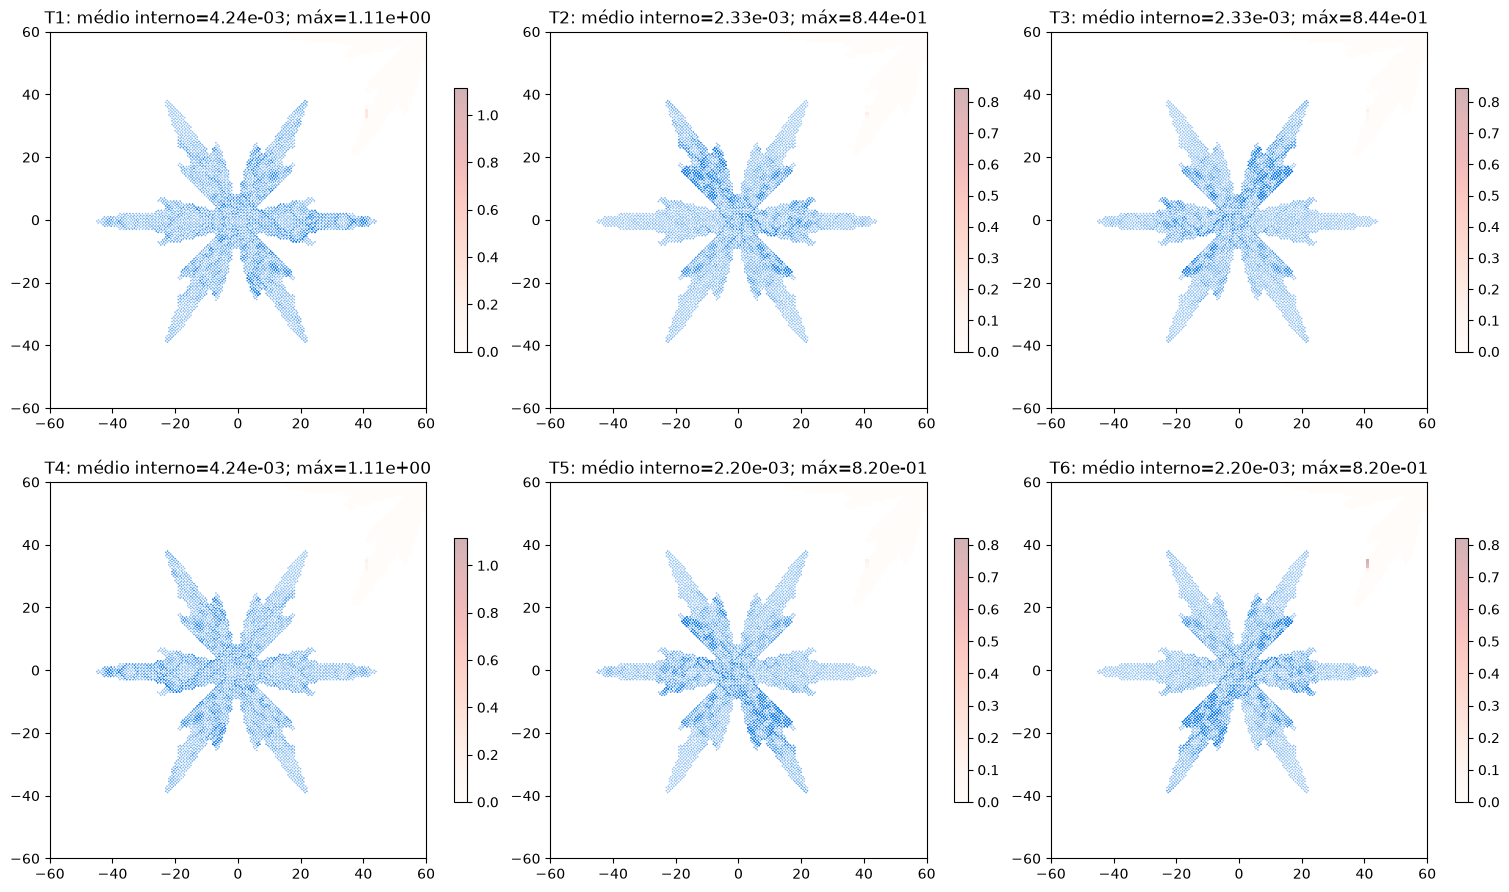

Mapas de fluxo e conservação salvos em ../figures/current_flow_each_terminal.png


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path('../data')
FIGURES_DIR = Path('../figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with np.load(DATA_DIR / 'geometries.npz') as geometry:
    mask = geometry['mask']
with np.load(DATA_DIR / 'local_deformed.npz') as local:
    current_links = local['current_links']
    link_positions = local['link_positions']
    site_positions = local['site_positions']
    divergences = local['divergences']
    internal_mean = local['internal_mean']
    internal_max = local['internal_max']

height, width = mask.shape
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

for source, ax in enumerate(axes.ravel()):
    divergence_grid = np.full((height, width), np.nan)
    for position, divergence in zip(site_positions, divergences[source]):
        x, y = np.rint(position).astype(int)
        mx = x + width // 2
        my = y + height // 2
        if 0 <= mx < width and 0 <= my < height:
            divergence_grid[mx, my] = abs(divergence)

    for (start, end), value in zip(link_positions, current_links[source]):
        mx = 0.5 * (start[0] + end[0])
        my = 0.5 * (start[1] + end[1])
        dx = end[0] - start[0]
        dy = end[1] - start[1]
        magnitude = min(1.0, abs(float(value)))
        ax.arrow(mx, my, 0.22 * dx * np.sign(value), 0.22 * dy * np.sign(value),
                 color='#0877e8', alpha=0.20 + 0.80 * magnitude,
                 width=0.014, head_width=0.14, length_includes_head=True)

    image = ax.imshow(divergence_grid.T, origin='lower', cmap='Reds', alpha=0.30,
                      interpolation='nearest')
    ax.set_xlim(-width // 2, width // 2)
    ax.set_ylim(-height // 2, height // 2)
    ax.set_aspect('equal')
    ax.set_title(f'T{source+1}: médio interno={internal_mean[source]:.2e}; máx={internal_max[source]:.2e}')
    fig.colorbar(image, ax=ax, fraction=0.035)

output = FIGURES_DIR / 'current_flow_each_terminal.png'
fig.savefig(output, dpi=220, bbox_inches='tight')
plt.show()
print(f'Mapas de fluxo e conservação salvos em {output}')